# Анализ центральности графа дружбы VK

**Задача:** для студентов учебной и параллельной групп построить граф дружеских связей в VK и определить:
- центральность по степени (количество связей);
- центральность по посредничеству (betweenness centrality);
- центральность по близости (closeness centrality);
- студента с наибольшим количеством связей.

### Модель графа

- **Вершина** — студент из исходного файла.
- **Ребро** — два студента являются друзьями в VK.

## 1. Установка библиотек

In [27]:
import os
import re
import time
from getpass import getpass
from itertools import combinations
import random
import colorsys
import math
import numpy as np

import pandas as pd
import networkx as nx
import requests
import matplotlib.pyplot as plt

## 2. Настройки

Подготовка файла "data_VK.xlsx" к загрузке

In [ ]:
INPUT_FILE = "data_VK.xlsx"

# Имя листа Excel. Для первого листа можно оставить 0
EXCEL_SHEET = 0

VK_API_VERSION = "5.199"

REQUEST_DELAY = 0.35

MAX_RETRIES = 3

## 3. Загрузка списка студентов

Ячейка пытается самостоятельно найти подходящий столбец с ID.

In [3]:
def load_students(path):
    path = str(path)
    ext = os.path.splitext(path)[1].lower()

    if ext in [".xlsx", ".xls"]:
        df = pd.read_excel(path, sheet_name=EXCEL_SHEET)
    elif ext == ".csv":
        try:
            df = pd.read_csv(path)
        except UnicodeDecodeError:
            df = pd.read_csv(path, encoding="cp1251")
    else:
        raise ValueError("Поддерживаются только XLSX, XLS и CSV.")

    df.columns = [str(c).strip().lower() for c in df.columns]

    id_candidates = ["id", "vk_id", "user_id", "userid", "вк id", "vk"]
    id_col = next((c for c in id_candidates if c in df.columns), None)

    if id_col is None:
        best_col = None
        best_score = 0
        for col in df.columns:
            values = df[col].dropna().astype(str)
            if len(values) == 0:
                continue
            score = values.str.contains(
                r"(?:vk\.com/)?(?:id)?\d+|^\d+$",
                case=False,
                regex=True
            ).mean()
            if score > best_score:
                best_score = score
                best_col = col

        if best_col is None or best_score < 0.5:
            raise ValueError(
                "Не удалось определить столбец с VK ID. "
                "Переименуйте его в 'id'."
            )
        id_col = best_col

    result = pd.DataFrame()
    result["id_raw"] = df[id_col]

    if "name" in df.columns:
        result["name"] = df["name"].fillna("").astype(str).str.strip()
    elif "фио" in df.columns:
        result["name"] = df["фио"].fillna("").astype(str).str.strip()
    else:
        result["name"] = ""

    if "group" in df.columns:
        result["group"] = df["group"].fillna("Не указана").astype(str).str.strip()
    elif "группа" in df.columns:
        result["group"] = df["группа"].fillna("Не указана").astype(str).str.strip()
    else:
        result["group"] = "Не указана"

    def parse_vk_id(value):
        s = str(value).strip()
        # URL вида https://vk.com/id123 или vk.com/id123
        m = re.search(r"(?:vk\.com/)(?:id)?(\d+)", s, re.I)
        if m:
            return int(m.group(1))
        # Просто число
        m = re.fullmatch(r"(\d+)", s)
        if m:
            return int(m.group(1))
        # id123
        m = re.fullmatch(r"id(\d+)", s, re.I)
        if m:
            return int(m.group(1))
        # VK юзернейм: буквы, цифры, точки, подчёркивания, дефисы (мин. 2 символа)
        m = re.fullmatch(r"[a-zA-Z0-9][a-zA-Z0-9_.\-]+", s)
        if m:
            return s  # строка — будет разрешена через users.get
        return pd.NA

    result["id"] = result["id_raw"].map(parse_vk_id)
    result = result.dropna(subset=["id"]).copy()
    # Не кастуем в int64 сейчас — юзернеймы будут разрешены через API

    result = result.drop_duplicates(subset=["id"], keep="first").reset_index(drop=True)

    return result

students = load_students(INPUT_FILE)

print(f"Количество студентов в выборке: {len(students)}")
display(students.head(10))

Количество студентов в выборке: 28


,id_raw,name,group,id
0,metonimiaa,,BSBO-10-26,metonimiaa
1,bignigga,,BSBO-12-26,bignigga
2,kotletosss,,BSBO-10-26,kotletosss
3,y.doyneko,,BSBO-12-26,y.doyneko
4,id422397933,,BSBO-10-26,422397933
5,saulinivan,,BSBO-12-26,saulinivan
6,antonlevn,,BSBO-10-26,antonlevn
7,dimitr101,,BSBO-12-26,dimitr101
8,s.abramov2,,BSBO-10-26,s.abramov2
9,ku_ku_riz,,BSBO-12-26,ku_ku_riz


## 4. Проверка выборки

In [4]:
print("Количество студентов по группам:")
display(students["group"].value_counts().rename_axis("group").to_frame("count"))

print("\nДубликаты ID:", students["id"].duplicated().sum())
print("Пропуски ID:", students["id"].isna().sum())

Количество студентов по группам:


,count
group,
BSBO-10-26,17
BSBO-12-26,11



Дубликаты ID: 0
Пропуски ID: 0


## 5. Токен VK API

Код ниже хранит токен только в памяти текущей сессии Jupyter.

In [5]:
VK_TOKEN = getpass("Введите VK access token: ").strip()

if not VK_TOKEN:
    raise ValueError("Токен не введён.")

## 6. Вызов VK API

Используются методы `users.get` для профилей и `friends.get` для списка друзей.

In [6]:
API_URL = "https://api.vk.com/method/"

session = requests.Session()

def vk_request(method, **params):
    params["access_token"] = VK_TOKEN
    params["v"] = VK_API_VERSION

    last_error = None

    for attempt in range(1, MAX_RETRIES + 1):
        try:
            response = session.get(
                API_URL + method,
                params=params,
                timeout=20
            )
            response.raise_for_status()
            data = response.json()

            if "error" in data:
                error = data["error"]
                code = error.get("error_code")
                msg = error.get("error_msg", "Неизвестная ошибка VK API")
                raise RuntimeError(f"VK API error {code}: {msg}")

            return data["response"]

        except Exception as exc:
            last_error = exc
            if attempt < MAX_RETRIES:
                time.sleep(attempt * 1.5)
            else:
                raise RuntimeError(
                    f"Не удалось выполнить запрос {method}: {last_error}"
                ) from last_error

## 7. Получение профилей студентов

Сохраняем только минимально необходимые сведения: ID, имя и фамилию. Дополнительные персональные поля не собираются.

In [7]:
student_identifiers = students["id"].tolist()  # числа и/или юзернеймы

profiles = []
identifier_order = []

for start in range(0, len(student_identifiers), 1000):
    batch = student_identifiers[start:start + 1000]
    resp = vk_request(
        "users.get",
        user_ids=",".join(map(str, batch))
    )
    profiles.extend(resp)
    identifier_order.extend(batch)
    time.sleep(REQUEST_DELAY)

profiles_df = pd.DataFrame(profiles)

if not profiles_df.empty:
    # Маппинг: оригинальный идентификатор (юзернейм или число) -> числовой id VK
    id_resolution = {orig: prof["id"] for orig, prof in zip(identifier_order, profiles)}

    students["id"] = students["id"].map(lambda x: id_resolution.get(x, x))
    students["id"] = pd.to_numeric(students["id"], errors="coerce")
    students = students.dropna(subset=["id"]).copy()
    students["id"] = students["id"].astype("int64")

    profiles_df["name_vk"] = (
        profiles_df["first_name"].fillna("") + " " +
        profiles_df["last_name"].fillna("")
    ).str.strip()

    if "deactivated" not in profiles_df.columns:
        profiles_df["deactivated"] = None

    students = students.drop(columns=["name"], errors="ignore").merge(
        profiles_df[["id", "name_vk", "deactivated"]],
        on="id",
        how="left"
    )

    students["name"] = students["name_vk"].fillna("")
    students = students.drop(columns=["name_vk"], errors="ignore")

else:
    students["name"] = students.get("name", "")
    students["deactivated"] = None

print(f"Загружено студентов: {len(students)}")
display(students.head())

Загружено студентов: 28


,id_raw,group,id,deactivated,name
0,metonimiaa,BSBO-10-26,214576903,None,Артем Кузьмин
1,bignigga,BSBO-12-26,447383697,None,Игорь Сусаров
2,kotletosss,BSBO-10-26,147436715,None,Мария Александрова
3,y.doyneko,BSBO-12-26,365680993,None,Юлия Дойнеко
4,id422397933,BSBO-10-26,422397933,None,Андрей Клейменов


## 8. Получение списков друзей

Для каждого студента запрашивается список его друзей. API может не вернуть список полностью или может отказать в доступе для конкретного профиля. Такие случаи фиксируются отдельно и не скрываются.

In [8]:
def get_all_friends(user_id, count=5000):
    all_friends = []
    offset = 0

    while True:
        response = vk_request(
            "friends.get",
            user_id=user_id,
            count=count,
            offset=offset
        )

        items = response.get("items", [])
        total = response.get("count", 0)

        all_friends.extend(items)

        if not items or len(all_friends) >= total or len(items) < count:
            break

        offset += len(items)
        time.sleep(REQUEST_DELAY)

    return set(all_friends)


friends_by_user = {}
api_errors = []

for i, user_id in enumerate(students["id"], start=1):
    try:
        friends_by_user[int(user_id)] = get_all_friends(int(user_id))
        print(f"[{i}/{len(students)}] ID {user_id}: "
              f"{len(friends_by_user[int(user_id)])} друзей")
    except Exception as exc:
        api_errors.append({
            "user_id": int(user_id),
            "error": str(exc)
        })
        friends_by_user[int(user_id)] = set()
        print(f"[{i}/{len(students)}] ID {user_id}: ОШИБКА — {exc}")

    time.sleep(REQUEST_DELAY)

errors_df = pd.DataFrame(api_errors)
print(f"\nОшибок API: {len(errors_df)}")
if not errors_df.empty:
    display(errors_df)

[1/28] ID 214576903: 126 друзей
[2/28] ID 447383697: 104 друзей
[3/28] ID 147436715: 112 друзей
[4/28] ID 365680993: 289 друзей
[5/28] ID 422397933: 5413 друзей
[6/28] ID 223966628: 153 друзей
[7/28] ID 708207289: 111 друзей
[8/28] ID 299547783: 272 друзей
[9/28] ID 354792455: 87 друзей
[10/28] ID 288851914: 105 друзей
[11/28] ID 437474057: 40 друзей
[12/28] ID 465105120: 181 друзей
[13/28] ID 193511426: ОШИБКА — Не удалось выполнить запрос friends.get: VK API error 30: This profile is private
[14/28] ID 198182178: ОШИБКА — Не удалось выполнить запрос friends.get: VK API error 30: This profile is private
[15/28] ID 229017385: 20 друзей
[16/28] ID 473310225: 177 друзей
[17/28] ID 133821410: 127 друзей
[18/28] ID 424935969: 30 друзей
[19/28] ID 172152768: 62 друзей
[20/28] ID 139159408: 275 друзей
[21/28] ID 677045683: 108 друзей
[22/28] ID 236434667: ОШИБКА — Не удалось выполнить запрос friends.get: VK API error 30: This profile is private
[23/28] ID 278508214: 105 друзей
[24/28] ID 392

,user_id,error
0,193511426,Не удалось выполнить запрос friends.get: VK AP...
1,198182178,Не удалось выполнить запрос friends.get: VK AP...
2,236434667,Не удалось выполнить запрос friends.get: VK AP...


## 9. Построение графа

Ребро добавляется только между двумя студентами из исходной выборки, если первый студент видит второго в своём списке друзей VK.

Для дружбы VK граф рассматривается как **неориентированный**: наличие связи `A — B` означает одно ребро независимо от того, из чьего списка друзей оно было обнаружено.

In [ ]:
student_id_set = set(students["id"].astype(int))

G = nx.Graph()

# Добавляем все вершины заранее, включая студентов без найденных связей
for _, row in students.iterrows():
    G.add_node(
        int(row["id"]),
        name=row["name"] if row["name"] else str(row["id"]),
        group=row["group"]
    )

# Проверяем только связи внутри выборки.
for user_id, friend_ids in friends_by_user.items():
    internal_friends = student_id_set.intersection(friend_ids)

    for friend_id in internal_friends:
        if int(user_id) != int(friend_id):
            G.add_edge(int(user_id), int(friend_id))

print("Вершин:", G.number_of_nodes())
print("Рёбер:", G.number_of_edges())
print("Компонент связности:", nx.number_connected_components(G))

Вершин: 28
Рёбер: 16
Компонент связности: 16


## 10. Таблица рёбер

Эта таблица показывает, кто с кем является другом внутри учебной выборки.

In [10]:
id_to_name = dict(zip(students["id"], students["name"]))
id_to_group = dict(zip(students["id"], students["group"]))

edges = []
for u, v in G.edges():
    edges.append({
        "id_1": u,
        "name_1": id_to_name.get(u, str(u)),
        "group_1": id_to_group.get(u, ""),
        "id_2": v,
        "name_2": id_to_name.get(v, str(v)),
        "group_2": id_to_group.get(v, "")
    })

edges_df = pd.DataFrame(edges)
display(edges_df)

,id_1,name_1,group_1,id_2,name_2,group_2
0,365680993,Юлия Дойнеко,BSBO-12-26,223966628,Иван Саулин,BSBO-12-26
1,365680993,Юлия Дойнеко,BSBO-12-26,299547783,Дмитрий Полуэктов,BSBO-12-26
2,422397933,Андрей Клейменов,BSBO-10-26,193511426,Александр Васильев,BSBO-10-26
3,422397933,Андрей Клейменов,BSBO-10-26,299547783,Дмитрий Полуэктов,BSBO-12-26
4,422397933,Андрей Клейменов,BSBO-10-26,437474057,Дмитрий Базлов,BSBO-10-26
5,422397933,Андрей Клейменов,BSBO-10-26,229017385,Кирилл Кучеренко,BSBO-10-26
6,422397933,Андрей Клейменов,BSBO-10-26,236434667,Александр Голоктионов,BSBO-12-26
7,223966628,Иван Саулин,BSBO-12-26,299547783,Дмитрий Полуэктов,BSBO-12-26
8,354792455,Сергей Абрамов,BSBO-10-26,278508214,Илья Руднев,BSBO-10-26
9,354792455,Сергей Абрамов,BSBO-10-26,241970575,Никита Марков,BSBO-10-26


## 11. Расчёт центральностей

Используются четыре показателя:

**Центральность по степени** — доля вершин, с которыми человек непосредственно связан. Для поиска человека с максимальным количеством связей дополнительно рассматривается обычная степень `degree`.

**Центральность по посредничеству** (`betweenness`) — показывает, насколько часто вершина оказывается на кратчайших путях между другими вершинами. Высокое значение характерно для человека, который может выступать связующим звеном между частями группы.

**Центральность по близости** (`closeness`) — показывает, насколько быстро вершина достижима от остальных связанных с ней вершин по кратчайшим путям.

**Центральность собственного вектора** (`eigenvector`) — учитывает не только количество связей, но и их «качество»: связь с высокоцентральным человеком даёт больше веса. Если граф несвязный, вычисляется внутри каждой компоненты.

Если граф распадается на несколько компонент, значения closeness и eigenvector нужно интерпретировать осторожно: вершины из разных компонент недостижимы друг из друга.

In [ ]:
degree = dict(G.degree())
degree_centrality = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G, normalized=True)
closeness = nx.closeness_centrality(G)

# Eigenvector centrality на несвязном графе вычисляется покомпонентно.
# eigenvector_centrality_numpy на полной матрице падает с TypeError (numpy argmax
# не работает с комплексными eigenvalues при наличии изолированных вершин).
eigenvector = {}
for component in nx.connected_components(G):
    sub = G.subgraph(component).copy()
    if sub.number_of_edges() == 0:
        for n in sub.nodes():
            eigenvector[n] = 0.0
    else:
        try:
            sub_ec = nx.eigenvector_centrality_numpy(sub)
            eigenvector.update(sub_ec)
        except Exception:
            for n in sub.nodes():
                eigenvector[n] = 0.0

results = students[["id", "name", "group"]].copy()
results["degree"] = results["id"].map(degree).fillna(0).astype(int)
results["degree_centrality"] = results["id"].map(degree_centrality).fillna(0)
results["betweenness_centrality"] = results["id"].map(betweenness).fillna(0)
results["closeness_centrality"] = results["id"].map(closeness).fillna(0)
results["eigenvector_centrality"] = results["id"].map(eigenvector).fillna(0)

results = results.sort_values(
    ["degree", "betweenness_centrality", "closeness_centrality"],
    ascending=False
).reset_index(drop=True)

display(
    results.style.format({
        "degree_centrality": "{:.4f}",
        "betweenness_centrality": "{:.4f}",
        "closeness_centrality": "{:.4f}",
        "eigenvector_centrality": "{:.4f}",
    })
)

## 12. Студент с наибольшим количеством связей

In [12]:
max_degree = results["degree"].max()
leaders = results[results["degree"] == max_degree].copy()

print(f"Максимальное количество связей: {max_degree}")
display(
    leaders[[
        "id", "name", "group", "degree",
        "degree_centrality",
        "betweenness_centrality",
        "closeness_centrality",
        "eigenvector_centrality",
    ]]
)

Максимальное количество связей: 5


,id,name,group,degree,degree_centrality,betweenness_centrality,closeness_centrality,eigenvector_centrality
0,422397933,Андрей Клейменов,BSBO-10-26,5,0.185185,0.048433,0.201646,0.0


## 13. Лидеры по трём видам центральности

In [13]:
print("ТОП по центральности по степени:")
display(results.sort_values("degree_centrality", ascending=False).head(10))

print("ТОП по центральности по посредничеству:")
display(
    results.sort_values("betweenness_centrality", ascending=False)
           .head(10)
)

print("ТОП по центральности по близости:")
display(
    results.sort_values("closeness_centrality", ascending=False)
           .head(10)
)

print("ТОП по центральности собственного вектора:")
display(
    results.sort_values("eigenvector_centrality", ascending=False)
           .head(10)
)

ТОП по центральности по степени:


,id,name,group,degree,degree_centrality,betweenness_centrality,closeness_centrality,eigenvector_centrality
0,422397933,Андрей Клейменов,BSBO-10-26,5,0.185185,0.048433,0.201646,0.0
1,299547783,Дмитрий Полуэктов,BSBO-12-26,3,0.111111,0.028490,0.164983,0.0
2,437474057,Дмитрий Базлов,BSBO-10-26,2,0.074074,0.000000,0.129630,0.0
3,236434667,Александр Голоктионов,BSBO-12-26,2,0.074074,0.000000,0.129630,0.0
4,365680993,Юлия Дойнеко,BSBO-12-26,2,0.074074,0.000000,0.113426,0.0
5,223966628,Иван Саулин,BSBO-12-26,2,0.074074,0.000000,0.113426,0.0
6,354792455,Сергей Абрамов,BSBO-10-26,2,0.074074,0.000000,0.074074,0.0
7,465105120,Илья Медведев,BSBO-12-26,2,0.074074,0.000000,0.074074,0.0
8,198182178,Александр Ершов,BSBO-12-26,2,0.074074,0.000000,0.074074,0.0
9,473310225,Лия Мартынова,BSBO-12-26,2,0.074074,0.000000,0.074074,0.0


ТОП по центральности по посредничеству:


,id,name,group,degree,degree_centrality,betweenness_centrality,closeness_centrality,eigenvector_centrality
0,422397933,Андрей Клейменов,BSBO-10-26,5,0.185185,0.048433,0.201646,0.0
1,299547783,Дмитрий Полуэктов,BSBO-12-26,3,0.111111,0.028490,0.164983,0.0
26,830638754,Клим Волохов,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
25,392942223,Ruslän Dächev,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
24,677045683,Руслан Аллабергенов,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
23,139159408,Даниил Нисанов,BSBO-12-26,0,0.000000,0.000000,0.000000,0.0
22,424935969,Владимир Романенко,BSBO-12-26,0,0.000000,0.000000,0.000000,0.0
21,133821410,Кирилл Дренин,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
20,288851914,Денис Давыдов,BSBO-12-26,0,0.000000,0.000000,0.000000,0.0
19,708207289,Ле Хиеп-Хый,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0


ТОП по центральности по близости:


,id,name,group,degree,degree_centrality,betweenness_centrality,closeness_centrality,eigenvector_centrality
0,422397933,Андрей Клейменов,BSBO-10-26,5,0.185185,0.048433,0.201646,0.0
1,299547783,Дмитрий Полуэктов,BSBO-12-26,3,0.111111,0.028490,0.164983,0.0
2,437474057,Дмитрий Базлов,BSBO-10-26,2,0.074074,0.000000,0.129630,0.0
3,236434667,Александр Голоктионов,BSBO-12-26,2,0.074074,0.000000,0.129630,0.0
12,193511426,Александр Васильев,BSBO-10-26,1,0.037037,0.000000,0.120988,0.0
13,229017385,Кирилл Кучеренко,BSBO-10-26,1,0.037037,0.000000,0.120988,0.0
4,365680993,Юлия Дойнеко,BSBO-12-26,2,0.074074,0.000000,0.113426,0.0
5,223966628,Иван Саулин,BSBO-12-26,2,0.074074,0.000000,0.113426,0.0
6,354792455,Сергей Абрамов,BSBO-10-26,2,0.074074,0.000000,0.074074,0.0
7,465105120,Илья Медведев,BSBO-12-26,2,0.074074,0.000000,0.074074,0.0


ТОП по центральности собственного вектора:


,id,name,group,degree,degree_centrality,betweenness_centrality,closeness_centrality,eigenvector_centrality
0,422397933,Андрей Клейменов,BSBO-10-26,5,0.185185,0.048433,0.201646,0.0
1,299547783,Дмитрий Полуэктов,BSBO-12-26,3,0.111111,0.028490,0.164983,0.0
26,830638754,Клим Волохов,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
25,392942223,Ruslän Dächev,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
24,677045683,Руслан Аллабергенов,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
23,139159408,Даниил Нисанов,BSBO-12-26,0,0.000000,0.000000,0.000000,0.0
22,424935969,Владимир Романенко,BSBO-12-26,0,0.000000,0.000000,0.000000,0.0
21,133821410,Кирилл Дренин,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0
20,288851914,Денис Давыдов,BSBO-12-26,0,0.000000,0.000000,0.000000,0.0
19,708207289,Ле Хиеп-Хый,BSBO-10-26,0,0.000000,0.000000,0.000000,0.0


## 14. Визуализация графа

Размер вершины пропорционален числу связей. Подписываются имена студентов.

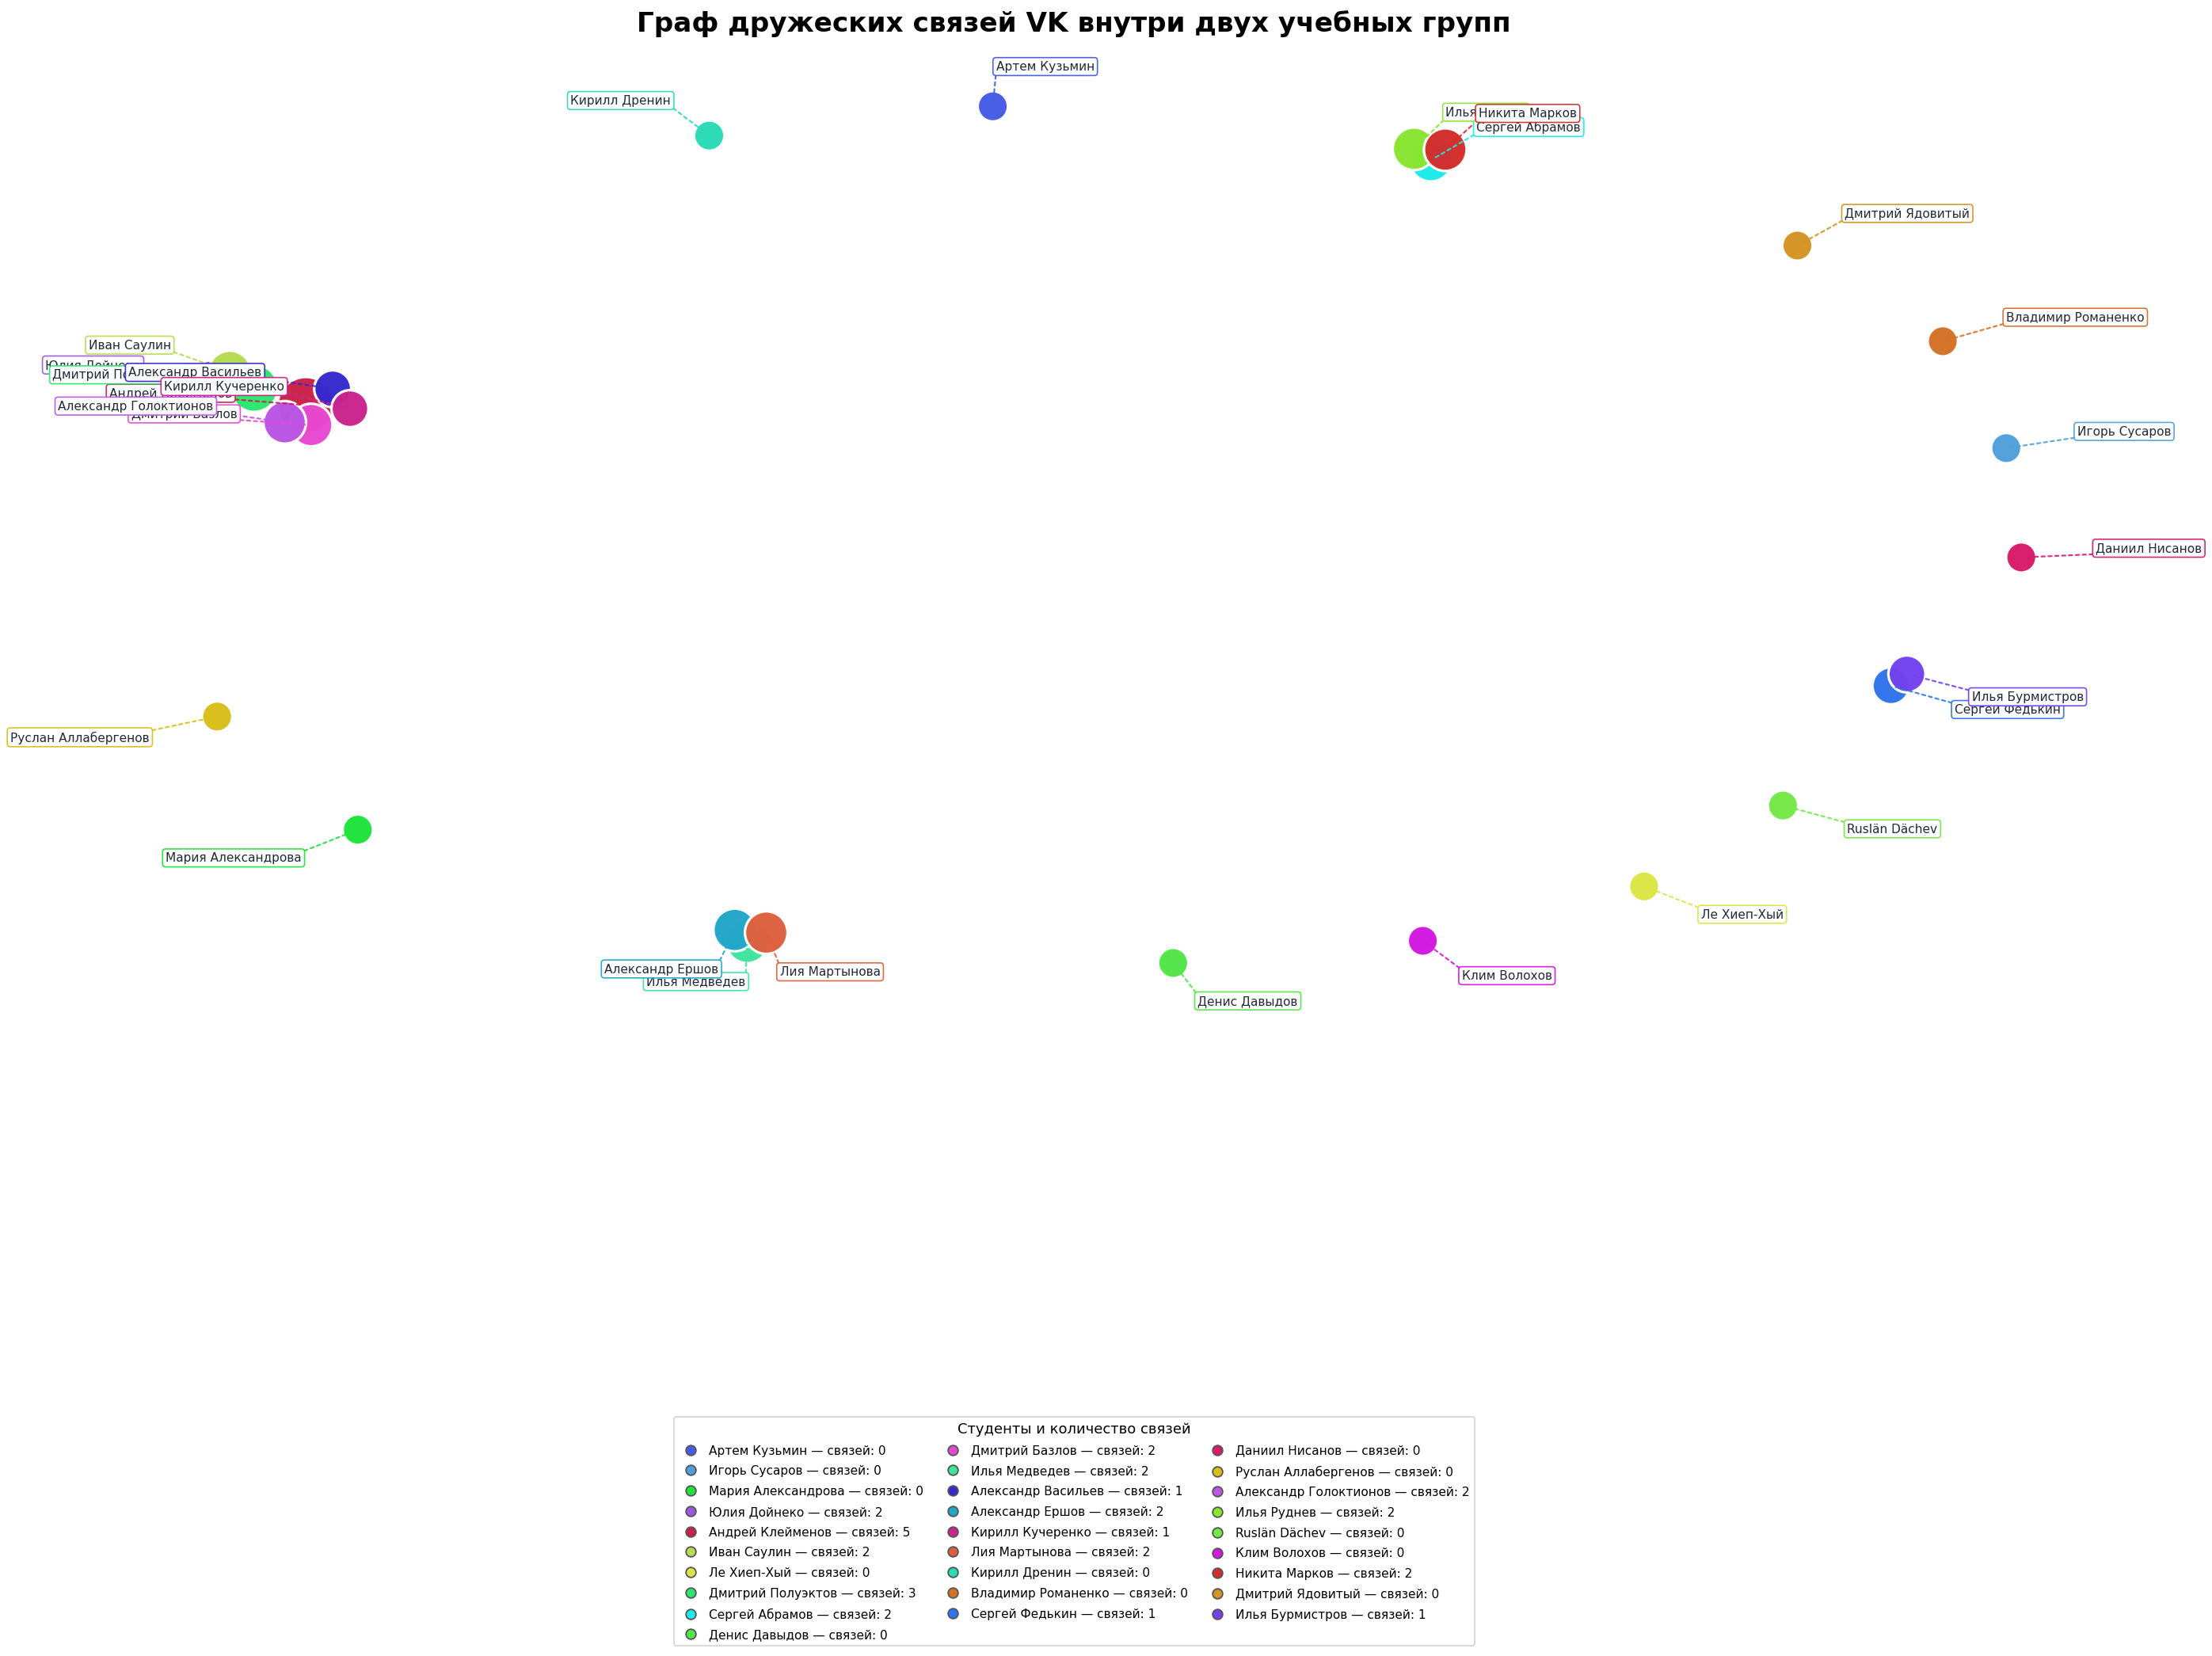

In [34]:
plt.rcParams["figure.dpi"] = 130
plt.rcParams["font.family"] = "DejaVu Sans"

if G.number_of_nodes() == 0:
    print("Граф пуст: нет вершин для отображения.")

else:
    nodes = list(G.nodes())
    n = len(nodes)

    fig, ax = plt.subplots(figsize=(23, 17))

    # Уникальные цвета вершин
    random.seed(42)
    hues = [i / n for i in range(n)]
    random.shuffle(hues)

    node_colors = {}
    for node, hue in zip(nodes, hues):
        saturation = random.uniform(0.65, 0.85)
        lightness = random.uniform(0.45, 0.62)
        rgb = colorsys.hls_to_rgb(hue, lightness, saturation)
        node_colors[node] = "#{:02x}{:02x}{:02x}".format(
            int(rgb[0] * 255),
            int(rgb[1] * 255),
            int(rgb[2] * 255)
        )

    # Расположение вершин
    pos = nx.spring_layout(
        G,
        seed=42,
        k=2.5 / math.sqrt(n),
        iterations=300,
        weight=None
    )

    degrees = dict(G.degree())
    node_sizes = [450 + 220 * degrees[node] for node in nodes]

    # Рёбра графа
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color="#9AA4B2",
        width=1.1,
        alpha=0.32
    )

    # Вершины
    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        nodelist=nodes,
        node_color=[node_colors[node] for node in nodes],
        node_size=node_sizes,
        edgecolors="white",
        linewidths=1.8,
        alpha=0.98
    )

    # Подписи рядом с маркерами и пунктирные линии-указатели
    rng = np.random.default_rng(42)

    for node in nodes:
        x, y = pos[node]
        name = str(G.nodes[node].get("name", node))

        # Направление подписи от центра графа наружу
        direction = np.array([x, y], dtype=float)
        norm = np.linalg.norm(direction)

        if norm > 0:
            direction /= norm
        else:
            direction = rng.normal(size=2)
            direction /= np.linalg.norm(direction)

        # Небольшое дополнительное смещение для уменьшения наложений
        direction += rng.normal(0, 0.22, size=2)
        direction /= np.linalg.norm(direction)

        offset = 0.075
        label_x = x + direction[0] * offset
        label_y = y + direction[1] * offset

        # Горизонтальное выравнивание в зависимости от направления
        ha = "left" if direction[0] >= 0 else "right"
        va = "bottom" if direction[1] >= 0 else "top"

        # Пунктирный указатель
        ax.annotate(
            "",
            xy=(x, y),
            xytext=(label_x, label_y),
            arrowprops=dict(
                arrowstyle="-",
                linestyle=(0, (2, 2)),
                color=node_colors[node],
                lw=1.2,
                alpha=0.9
            ),
            zorder=3
        )

        # Текст с белым фоном
        ax.text(
            label_x,
            label_y,
            name,
            fontsize=8.5,
            color="#202938",
            ha=ha,
            va=va,
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor=node_colors[node],
                linewidth=0.9,
                alpha=0.96
            ),
            zorder=4
        )

    # Нижняя легенда: имя и количество связей
    legend_handles = []

    for node in nodes:
        name = str(G.nodes[node].get("name", node))
        legend_handles.append(
            plt.Line2D(
                [0], [0],
                marker="o",
                linestyle="None",
                markerfacecolor=node_colors[node],
                markeredgecolor="#555555",
                markersize=7,
                label=f"{name} — связей: {degrees[node]}"
            )
        )

    legend_columns = min(4, max(1, math.ceil(n / 12)))

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.012),
        ncol=legend_columns,
        fontsize=8.5,
        frameon=True,
        fancybox=True,
        title="Студенты и количество связей",
        title_fontsize=10,
        columnspacing=1.4,
        handletextpad=0.5,
        labelspacing=0.7
    )

    ax.set_title(
        "Граф дружеских связей VK внутри двух учебных групп",
        fontsize=19,
        fontweight="bold",
        pad=22
    )

    ax.axis("off")

    # Оставляем место для подписей и легенды
    fig.subplots_adjust(
        left=0.06,
        right=0.94,
        top=0.92,
        bottom=min(0.42, 0.12 + 0.025 * math.ceil(n / legend_columns))
    )

    plt.show()


## 15. Дополнительный анализ компонент

Посмотрим, распадается ли группа на отдельные сообщества.

In [15]:
components = sorted(nx.connected_components(G), key=len, reverse=True)

component_rows = []
for idx, component in enumerate(components, start=1):
    for node in component:
        component_rows.append({
            "component": idx,
            "component_size": len(component),
            "id": node,
            "name": id_to_name.get(node, str(node)),
            "group": id_to_group.get(node, "")
        })

components_df = pd.DataFrame(component_rows)
display(components_df)

,component,component_size,id,name,group
0,1,8,365680993,Юлия Дойнеко,BSBO-12-26
1,1,8,193511426,Александр Васильев,BSBO-10-26
2,1,8,223966628,Иван Саулин,BSBO-12-26
3,1,8,299547783,Дмитрий Полуэктов,BSBO-12-26
4,1,8,437474057,Дмитрий Базлов,BSBO-10-26
5,1,8,229017385,Кирилл Кучеренко,BSBO-10-26
6,1,8,236434667,Александр Голоктионов,BSBO-12-26
7,1,8,422397933,Андрей Клейменов,BSBO-10-26
8,2,3,241970575,Никита Марков,BSBO-10-26
9,2,3,278508214,Илья Руднев,BSBO-10-26


## 16. Сохранение результатов

In [16]:
os.makedirs("vk_graph_results", exist_ok=True)

results.to_csv(
    "vk_graph_results/centrality_results.csv",
    index=False,
    encoding="utf-8-sig"
)

edges_df.to_csv(
    "vk_graph_results/edges.csv",
    index=False,
    encoding="utf-8-sig"
)

components_df.to_csv(
    "vk_graph_results/components.csv",
    index=False,
    encoding="utf-8-sig"
)

if not errors_df.empty:
    errors_df.to_csv(
        "vk_graph_results/api_errors.csv",
        index=False,
        encoding="utf-8-sig"
    )

with pd.ExcelWriter(
    "vk_graph_results/vk_graph_analysis.xlsx",
    engine="openpyxl"
) as writer:
    results.to_excel(writer, sheet_name="Centrality", index=False)
    edges_df.to_excel(writer, sheet_name="Edges", index=False)
    components_df.to_excel(writer, sheet_name="Components", index=False)
    if not errors_df.empty:
        errors_df.to_excel(writer, sheet_name="API_errors", index=False)

print("Результаты сохранены в папке vk_graph_results/")

Результаты сохранены в папке vk_graph_results/
